# Hackathon – Dataset C (COVID vaccine) · Notebook 07 of 09
## Unseen hold-out evaluation, bootstrap uncertainty, robustness to assumptions

**Module:** 7PAM2002 – University of Hertfordshire · **GitHub:** `<add link>` · **Colab:** `<add link>` · **Author of this notebook:** `<name>`

**Goal of the project:** predict which residents will accept a COVID vaccine and decide who to post a dose to so that the town's **total
cost (vaccines + hospitalisations)** is as small as possible.

<details><summary><b>The nine notebooks (run them in this order)</b></summary>

| # | Notebook | Content |
|---|---|---|
| 01 | `01_Problem_Framing_and_Cost_Metric.ipynb` | Problem framing and the task-specific cost metric |
| 02 | `02_EDA_Data_Quality.ipynb` | EDA part 1 – overview, target, missing values, data quality, train/test shift |
| 03 | `03_EDA_Feature_Relationships.ipynb` | EDA part 2 – distributions, associations, interactions, cost drivers |
| 04 | `04_Preprocessing.ipynb` | Pre-processing – cleaning, feature engineering, comparing four options |
| 05 | `05_Model_Tuning.ipynb` | Modelling – six model families and hyper-parameter tuning |
| 06 | `06_Cross_Validation_and_Decision_Strategy.ipynb` | Repeated cross-validation and turning probabilities into decisions |
| 07 | `07_Holdout_Evaluation_and_Robustness.ipynb` | Unseen hold-out evaluation, bootstrap uncertainty, robustness to assumptions |
| 08 | `08_Final_Selection_and_Submission.ipynb` | Final model selection and the five ranked submission files |
| 09 | `09_Explainable_AI_and_Conclusions.ipynb` | Explainable AI (SHAP, odds ratios, permutation importance) and conclusions |

Shared code (data loading, cost metric, cleaning, pipelines, models, evaluation helpers) lives in **`hackathon_utils.py`** so every notebook uses
exactly the same definitions. Results are passed from one notebook to the next through the **`artifacts/`** folder.
</details>


In [1]:
# ---- Set-up: run from the repository folder locally, or in Google Colab ----
import sys, os, subprocess, importlib, importlib.util
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/<your-organisation>/<your-repository>.git'   # <- set this once for Colab

if IN_COLAB and not Path('hackathon_utils.py').exists():
    subprocess.run(['git', 'clone', '-q', REPO_URL, 'repo'], check=True)   # get code, data and artifacts
    os.chdir('repo')

for pkg in ['xgboost', 'lightgbm', 'catboost', 'shap']:                    # CatBoost is not pre-installed on Colab
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from hackathon_utils import *            # shared data, cost metric, pipelines, models and helpers
print('train:', train_raw.shape, '| test:', test_raw.shape, '| scikit-learn', sklearn.__version__)

train: (4756, 31) | test: (4749, 30) | scikit-learn 1.6.1


In [2]:
from IPython.display import display

In [3]:
BEST_PREP = load_json('best_prep.json')          # notebook 04
TUNED_PARAMS = load_json('tuned_params.json')    # notebook 05
TUNED = build_tuned_models(BEST_PREP, TUNED_PARAMS)
print(list(TUNED))

['Baseline: prior only', 'Logistic Regression', 'Random Forest', 'Random Forest + isotonic', 'XGBoost', 'LightGBM', 'CatBoost', 'Ensemble (LR+XGB+LGBM+Cat)']


## 7. Performance on the unseen hold-out set
Every tuned model is now re-fitted on the full development set and scored **once** on the 20 % hold-out data that played no role so far.

In [4]:
HOLD_PROBS, HOLD_MODELS, hold_rows = {}, {}, []
for name in MODEL_ORDER:
    m = clone(TUNED[name]).fit(X_dev, y_dev)
    HOLD_MODELS[name] = m
    HOLD_PROBS[name] = m.predict_proba(X_hold)[:, 1]
    hold_rows.append({'model': name, **evaluate_probs(y_hold, HOLD_PROBS[name], X_hold)})
hold_table = pd.DataFrame(hold_rows).set_index('model')

yh = y_hold.to_numpy()
ref_rows = {'Rule: send to nobody': np.zeros_like(yh), 'Rule: send to everybody': np.ones_like(yh),
            'Rule: send if doctor recommended': X_hold['doctor_recc_covid'].to_numpy(), 'Oracle (perfect knowledge)': yh}
ref_table = pd.DataFrame({k: {'$/resident': cost_per_person(yh, v, X_hold)} for k, v in ref_rows.items()}).T

show_cols = ['ROC-AUC', 'log-loss', 'F1@0.5', '$/resident [thr 0.5]', '$/resident [single thr]', '$/resident [personal thr]',
             '% saving captured [personal thr]']
hold_table.to_csv(ART_DIR / 'holdout_table.csv')
pd.DataFrame(HOLD_PROBS, index=X_hold.index).to_csv(ART_DIR / 'holdout_probs.csv')
display(hold_table[show_cols].round(3))
ref_table.round(1)

,ROC-AUC,log-loss,F1@0.5,$/resident [thr 0.5],$/resident [single thr],$/resident [personal thr],% saving captured [personal thr]
model,,,,,,,
Baseline: prior only,0.500,0.632,0.000,3943.950,3943.950,3433.085,46.504
Logistic Regression,0.867,0.422,0.700,3259.694,3244.965,3201.806,67.558
Random Forest,0.856,0.432,0.673,3315.065,3252.963,3242.463,63.857
Random Forest + isotonic,0.856,0.432,0.671,3316.080,3277.063,3226.229,65.334
XGBoost,0.865,0.420,0.710,3258.113,3234.711,3207.456,67.043
LightGBM,0.865,0.420,0.703,3265.770,3245.952,3205.272,67.242
CatBoost,0.859,0.428,0.698,3273.341,3274.503,3230.026,64.989
Ensemble (LR+XGB+LGBM+Cat),0.867,0.419,0.705,3267.611,3233.680,3222.248,65.697


,$/resident
Rule: send to nobody,3944.0
Rule: send to everybody,3855.4
Rule: send if doctor recommended,3484.4
Oracle (perfect knowledge),2845.4


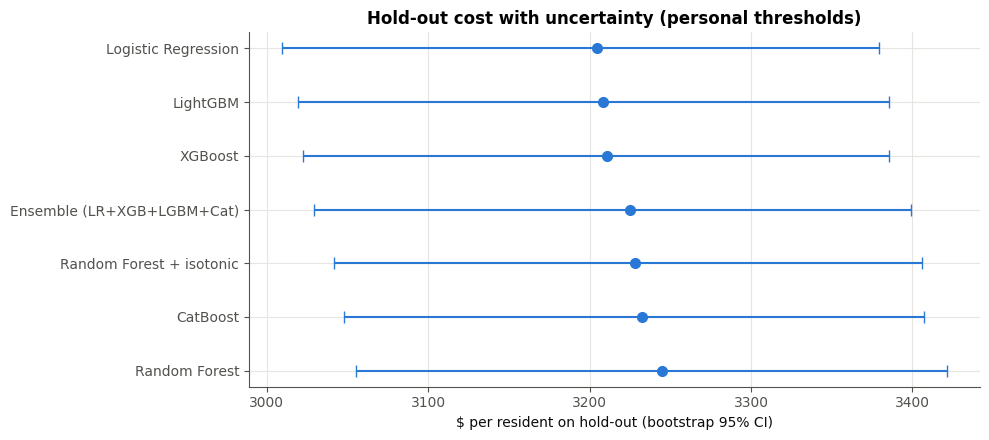

,$/resident,95% CI low,95% CI high,P(better than Ensemble)
Logistic Regression,3204.402,3009.639,3379.076,0.910
LightGBM,3208.411,3019.239,3385.432,0.955
XGBoost,3210.636,3022.336,3385.678,0.977
Ensemble (LR+XGB+LGBM+Cat),3225.353,3029.416,3399.196,0.000
Random Forest + isotonic,3228.477,3041.506,3405.739,0.400
CatBoost,3232.633,3048.195,3407.430,0.260
Random Forest,3244.719,3055.406,3421.300,0.071


In [5]:
# Bootstrap the hold-out set: how certain are the differences between models? (paired resampling)
rng = np.random.default_rng(RANDOM_STATE)
B = 1000
cand = [m for m in MODEL_ORDER if not m.startswith('Baseline')]
send_hold = {m: decide(HOLD_PROBS[m], X_hold, 'personal thr') for m in cand}
p_h = MAIN.p_unvacc(X_hold)

def person_costs(y, send, p, ve=MAIN.ve):
    y, send = y.astype(bool), send.astype(bool)
    return VACCINE_COST * (send | y) + HOSP_COST * p * np.where(send & y, 1 - ve, 1.0)

pc = {m: person_costs(yh, send_hold[m], p_h) for m in cand}
boot = {m: [] for m in cand}
for _ in range(B):
    idx = rng.integers(0, len(yh), len(yh))
    for m in cand:
        boot[m].append(pc[m][idx].mean())
boot = pd.DataFrame(boot)
ref_model = 'Ensemble (LR+XGB+LGBM+Cat)'
boot_summary = pd.DataFrame({
    '$/resident': boot.mean(), '95% CI low': boot.quantile(0.025), '95% CI high': boot.quantile(0.975),
    f'P(better than {ref_model.split(" (")[0]})': (boot.lt(boot[ref_model], axis=0)).mean(),
}).sort_values('$/resident')

fig, ax = plt.subplots(figsize=(10, 4.5))
order = boot_summary.index
ax.errorbar(boot_summary['$/resident'], range(len(order)),
            xerr=[boot_summary['$/resident'] - boot_summary['95% CI low'], boot_summary['95% CI high'] - boot_summary['$/resident']],
            fmt='o', color=BLUE, capsize=4, ms=7)
ax.set_yticks(range(len(order)), order); ax.invert_yaxis()
ax.set_xlabel('$ per resident on hold-out (bootstrap 95% CI)'); ax.set_title('Hold-out cost with uncertainty (personal thresholds)')
plt.tight_layout(); savefig('07_holdout_bootstrap'); plt.show()
boot_summary.round(3)

### 7.1 Robustness: what if the marker's hospitalisation assumptions differ from ours?
We do not know exactly which hospitalisation probabilities the teaching team will use. Each candidate submission (model × decision strategy) is
therefore scored on the hold-out set under **all five scenarios**. Decisions are always made with our *main* assumptions (as they would be for
the real submission) – only the scoring changes.

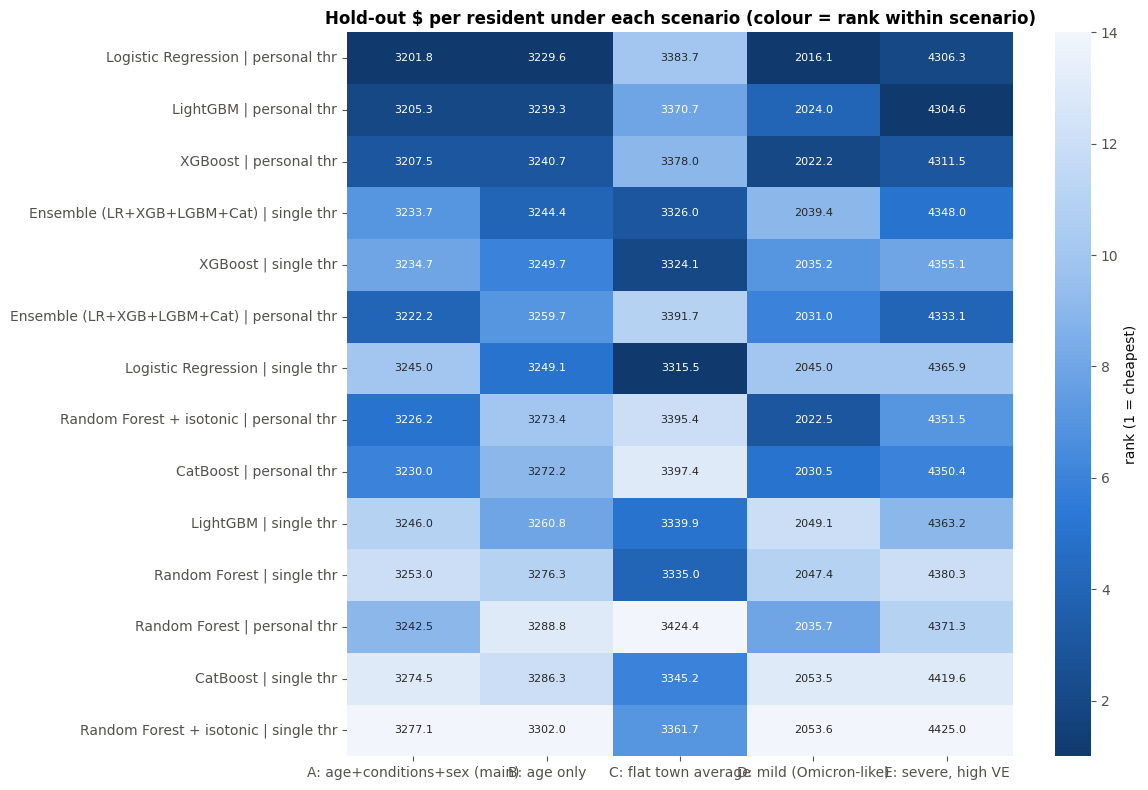

,A: age+conditions+sex (main),B: age only,C: flat town average,D: mild (Omicron-like),"E: severe, high VE",mean rank
candidate,,,,,,
Logistic Regression | personal thr,3201.8,3229.6,3383.7,2016.1,4306.3,3.0
LightGBM | personal thr,3205.3,3239.3,3370.7,2024.0,4304.6,3.4
XGBoost | personal thr,3207.5,3240.7,3378.0,2022.2,4311.5,4.0
Ensemble (LR+XGB+LGBM+Cat) | single thr,3233.7,3244.4,3326.0,2039.4,4348.0,5.6
XGBoost | single thr,3234.7,3249.7,3324.1,2035.2,4355.1,6.2
Ensemble (LR+XGB+LGBM+Cat) | personal thr,3222.2,3259.7,3391.7,2031.0,4333.1,6.4
Logistic Regression | single thr,3245.0,3249.1,3315.5,2045.0,4365.9,7.2
Random Forest + isotonic | personal thr,3226.2,3273.4,3395.4,2022.5,4351.5,7.4
CatBoost | personal thr,3230.0,3272.2,3397.4,2030.5,4350.4,7.8


In [6]:
robust_rows = []
for m in cand:
    for s in ['single thr', 'personal thr']:
        send = decide(HOLD_PROBS[m], X_hold, s, MAIN)
        robust_rows.append({'candidate': f'{m} | {s}',
                            **{sc.name: cost_per_person(yh, send, X_hold, sc) for sc in SCENARIOS}})
robust = pd.DataFrame(robust_rows).set_index('candidate')
robust_rank = robust.rank(axis=0)
robust['mean rank'] = robust_rank.mean(axis=1)
robust = robust.sort_values('mean rank')

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(robust_rank.loc[robust.index], annot=robust.drop(columns='mean rank').round(1), fmt='', cmap=SEQ_CMAP.reversed(),
            cbar_kws={'label': 'rank (1 = cheapest)'}, ax=ax, annot_kws={'size': 8})
ax.set_title('Hold-out $ per resident under each scenario (colour = rank within scenario)'); ax.set_ylabel('')
plt.tight_layout(); savefig('07_robustness'); plt.show()
robust.to_csv(ART_DIR / 'robustness.csv')
robust.round(1)

**Reading the robustness table.** Under four of the five scenarios (age + conditions, age only, mild, severe) the *personal-threshold*
candidates are cheapest. Only if the marker gives **every resident the same hospitalisation probability** (scenario C) does a single threshold win –
because then the personal rule is optimising against risk differences the marker ignores. Our choice of five submissions therefore keeps a
single-threshold model as a **hedge**.

**Next:** notebook 08 combines cross-validation, hold-out and robustness results to choose the five submissions.